In [ ]:
import pandas as pd
import numpy as np
import random

random.seed(42)
np.random.seed(42)

print("ClaimsPilot NLP environment ready!")

ClaimsPilot NLP environment ready!


In [ ]:
parts = {
    "front_bumper": {
        "fr": "Le pare-chocs avant est endommagé.",
        "en": "The front bumper is damaged."
    },
    "rear_bumper": {
        "fr": "Le pare-chocs arrière est endommagé.",
        "en": "The rear bumper is damaged."
    },
    "door": {
        "fr": "La portière est endommagée.",
        "en": "The car door is damaged."
    },
    "headlight": {
        "fr": "Le phare est cassé.",
        "en": "The headlight is broken."
    },
    "windshield": {
        "fr": "Le pare-brise est fissuré.",
        "en": "The windshield is cracked."
    }
}

part_names = list(parts.keys())
claims = []

for i in range(200):
    language = "fr" if i < 150 else "en"
    described_part = random.choice(part_names)

    # Balanced classes: 100 consistent, 100 inconsistent
    is_consistent = i % 2 == 0

    if is_consistent:
        photo_part = described_part
        label = "consistent"
    else:
        photo_part = random.choice(
            [p for p in part_names if p != described_part]
        )
        label = "inconsistent"

    claims.append({
        "claim_id": f"C{i+1:03d}",
        "language": language,
        "text": parts[described_part][language],
        "photo_parts": photo_part,
        "described_parts": described_part,
        "label": label
    })

df = pd.DataFrame(claims)
df.head(10)

,claim_id,language,text,photo_parts,described_parts,label
0,C001,fr,Le pare-chocs avant est endommagé.,front_bumper,front_bumper,consistent
1,C002,fr,Le pare-chocs avant est endommagé.,headlight,front_bumper,inconsistent
2,C003,fr,Le pare-chocs arrière est endommagé.,rear_bumper,rear_bumper,consistent
3,C004,fr,Le pare-chocs arrière est endommagé.,door,rear_bumper,inconsistent
4,C005,fr,Le pare-chocs avant est endommagé.,front_bumper,front_bumper,consistent
5,C006,fr,Le pare-brise est fissuré.,front_bumper,windshield,inconsistent
6,C007,fr,Le pare-brise est fissuré.,windshield,windshield,consistent
7,C008,fr,Le phare est cassé.,front_bumper,headlight,inconsistent
8,C009,fr,Le pare-chocs avant est endommagé.,front_bumper,front_bumper,consistent
9,C010,fr,Le pare-chocs avant est endommagé.,door,front_bumper,inconsistent


In [ ]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nLanguage distribution:")
print(df["language"].value_counts())

print("\nDuplicate claim IDs:")
print(df["claim_id"].duplicated().sum())

print("\nLabel validation:")
expected = df["photo_parts"] == df["described_parts"]
actual = df["label"] == "consistent"
print("Incorrect labels:", (expected != actual).sum())

Dataset shape: (200, 6)

Missing values:
claim_id           0
language           0
text               0
photo_parts        0
described_parts    0
label              0
dtype: int64

Label distribution:
label
consistent      100
inconsistent    100
Name: count, dtype: int64

Language distribution:
language
fr    150
en     50
Name: count, dtype: int64

Duplicate claim IDs:
0

Label validation:
Incorrect labels: 0


In [ ]:
df.to_csv(
    "synthetic_claims_v1.csv",
    index=False,
    encoding="utf-8"
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:
import random
import pandas as pd

random.seed(42)

damage_descriptions = {
    "front_bumper": {
        "fr": [
            "Le pare-chocs avant est rayé.",
            "J'ai remarqué une bosse sur mon pare-chocs avant.",
            "Le devant de ma voiture a été endommagé.",
            "Mon pare-chocs avant a été abîmé lors du choc."
        ],
        "en": [
            "My front bumper was scratched.",
            "The front bumper was damaged in the accident.",
            "There is a dent on the front bumper.",
            "The front of my car was damaged."
        ]
    },
    "rear_bumper": {
        "fr": [
            "Le pare-chocs arrière est endommagé.",
            "Une voiture a abîmé mon pare-chocs arrière.",
            "J'ai une bosse à l'arrière de ma voiture.",
            "Mon pare-chocs arrière a été rayé."
        ],
        "en": [
            "My rear bumper was damaged.",
            "Another car hit my rear bumper.",
            "There is a dent on the rear bumper.",
            "The back bumper was scratched."
        ]
    },
    "door": {
        "fr": [
            "La portière gauche est rayée.",
            "Ma portière a été enfoncée.",
            "Une voiture a heurté la porte de mon véhicule.",
            "J'ai découvert une rayure sur ma portière."
        ],
        "en": [
            "My car door was scratched.",
            "There is a dent in the car door.",
            "Another vehicle hit my door.",
            "The side door was damaged."
        ]
    },
    "headlight": {
        "fr": [
            "Mon phare avant est cassé.",
            "Le phare a été fissuré pendant l'accident.",
            "J'ai constaté des dégâts sur mon phare.",
            "Le choc a endommagé le phare de ma voiture."
        ],
        "en": [
            "My headlight is broken.",
            "The accident cracked my headlight.",
            "There is visible damage to the headlight.",
            "The front light was damaged."
        ]
    },
    "windshield": {
        "fr": [
            "Mon pare-brise est fissuré.",
            "Une pierre a endommagé mon pare-brise.",
            "J'ai découvert une fissure sur le pare-brise.",
            "Le pare-brise a été cassé pendant l'accident."
        ],
        "en": [
            "My windshield is cracked.",
            "A stone damaged my windshield.",
            "There is a crack in the windshield.",
            "The accident damaged my windshield."
        ]
    }
}

contexts = {
    "fr": [
        "Après un accident dans un parking,",
        "Suite à une collision,",
        "Hier soir,",
        "En sortant du garage,",
        "Après avoir retrouvé ma voiture,"
    ],
    "en": [
        "After an accident in a parking lot,",
        "Following a collision,",
        "Yesterday evening,",
        "While leaving the garage,",
        "After returning to my car,"
    ]
}

records = []
parts = list(damage_descriptions.keys())

for i in range(200):
    language = "fr" if i < 150 else "en"
    described_part = random.choice(parts)

    description = random.choice(
        damage_descriptions[described_part][language]
    )

    context = random.choice(contexts[language])
    text = f"{context} {description[0].lower() + description[1:]}"

    is_consistent = i % 2 == 0

    if is_consistent:
        photo_part = described_part
        label = "consistent"
    else:
        photo_part = random.choice(
            [p for p in parts if p != described_part]
        )
        label = "inconsistent"

    records.append({
        "claim_id": f"C{i+1:03d}",
        "language": language,
        "text": text,
        "photo_parts": photo_part,
        "described_parts": described_part,
        "label": label
    })

df_v2 = pd.DataFrame(records)

display(df_v2.head(10))

,claim_id,language,text,photo_parts,described_parts,label
0,C001,fr,"Hier soir, le pare-chocs avant est rayé.",front_bumper,front_bumper,consistent
1,C002,fr,"Suite à une collision, une voiture a abîmé mon...",front_bumper,rear_bumper,inconsistent
2,C003,fr,"Après avoir retrouvé ma voiture, mon pare-bris...",windshield,windshield,consistent
3,C004,fr,"Après un accident dans un parking, mon phare a...",front_bumper,headlight,inconsistent
4,C005,fr,"Après avoir retrouvé ma voiture, une voiture a...",rear_bumper,rear_bumper,consistent
5,C006,fr,"Après avoir retrouvé ma voiture, mon pare-bris...",rear_bumper,windshield,inconsistent
6,C007,fr,"Suite à une collision, le pare-brise a été cas...",windshield,windshield,consistent
7,C008,fr,"Après un accident dans un parking, j'ai consta...",rear_bumper,headlight,inconsistent
8,C009,fr,"Hier soir, j'ai constaté des dégâts sur mon ph...",headlight,headlight,consistent
9,C010,fr,"Hier soir, une voiture a abîmé mon pare-chocs ...",front_bumper,rear_bumper,inconsistent


In [ ]:
print("Dataset shape:", df_v2.shape)

print("\nMissing values:")
print(df_v2.isnull().sum())

print("\nClass distribution:")
print(df_v2["label"].value_counts())

print("\nLanguage distribution:")
print(df_v2["language"].value_counts())

print("\nDuplicate claim IDs:")
print(df_v2["claim_id"].duplicated().sum())

print("\nDuplicate descriptions:")
print(df_v2["text"].duplicated().sum())

print("\nUnique descriptions:")
print(df_v2["text"].nunique())

expected = df_v2["photo_parts"] == df_v2["described_parts"]
actual = df_v2["label"] == "consistent"

print("\nIncorrect labels:", (expected != actual).sum())

assert len(df_v2) == 200
assert df_v2["claim_id"].is_unique
assert df_v2.isnull().sum().sum() == 0
assert (expected == actual).all()

print("\nAll basic validation checks passed!")

Dataset shape: (200, 6)

Missing values:
claim_id           0
language           0
text               0
photo_parts        0
described_parts    0
label              0
dtype: int64

Class distribution:
label
consistent      100
inconsistent    100
Name: count, dtype: int64

Language distribution:
language
fr    150
en     50
Name: count, dtype: int64

Duplicate claim IDs:
0

Duplicate descriptions:
79

Unique descriptions:
121

Incorrect labels: 0

All basic validation checks passed!


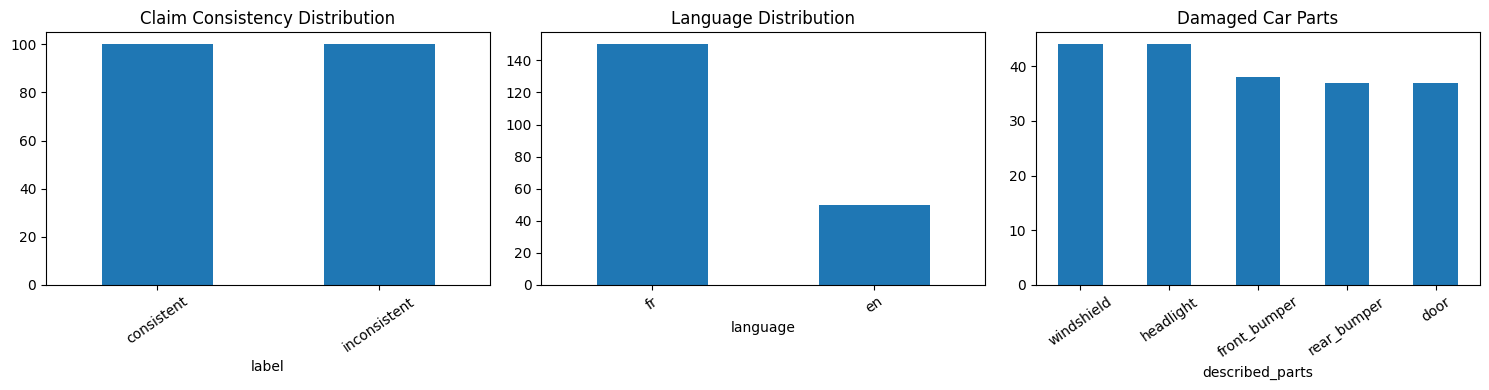

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df_v2["label"].value_counts().plot(
    kind="bar",
    ax=axes[0],
    title="Claim Consistency Distribution"
)

df_v2["language"].value_counts().plot(
    kind="bar",
    ax=axes[1],
    title="Language Distribution"
)

df_v2["described_parts"].value_counts().plot(
    kind="bar",
    ax=axes[2],
    title="Damaged Car Parts"
)

for ax in axes:
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

In [ ]:
df_v2.to_csv(
    "synthetic_claims_v2.csv",
    index=False,
    encoding="utf-8"
)

print("Improved dataset saved!")

Improved dataset saved!


In [ ]:
df_model = df_v2.copy()

df_model["model_input"] = (
    "CLAIM: " + df_model["text"] +
    " PHOTO_DAMAGE: " + df_model["photo_parts"]
)

X = df_model["model_input"]
y = df_model["label"]

display(df_model[
    ["model_input", "label"]
].head())

,model_input,label
0,"CLAIM: Hier soir, le pare-chocs avant est rayé...",consistent
1,"CLAIM: Suite à une collision, une voiture a ab...",inconsistent
2,"CLAIM: Après avoir retrouvé ma voiture, mon pa...",consistent
3,"CLAIM: Après un accident dans un parking, mon ...",inconsistent
4,"CLAIM: Après avoir retrouvé ma voiture, une vo...",consistent


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

nlp_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2)
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

nlp_model.fit(X_train, y_train)

print("NLP model trained successfully!")

NLP model trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred = nlp_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    pos_label="inconsistent",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    pos_label="inconsistent",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    pos_label="inconsistent",
    zero_division=0
)

print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1 Score:", round(f1, 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.5
Precision: 0.5
Recall: 0.55
F1 Score: 0.524

Classification Report:
              precision    recall  f1-score   support

  consistent       0.50      0.45      0.47        20
inconsistent       0.50      0.55      0.52        20

    accuracy                           0.50        40
   macro avg       0.50      0.50      0.50        40
weighted avg       0.50      0.50      0.50        40



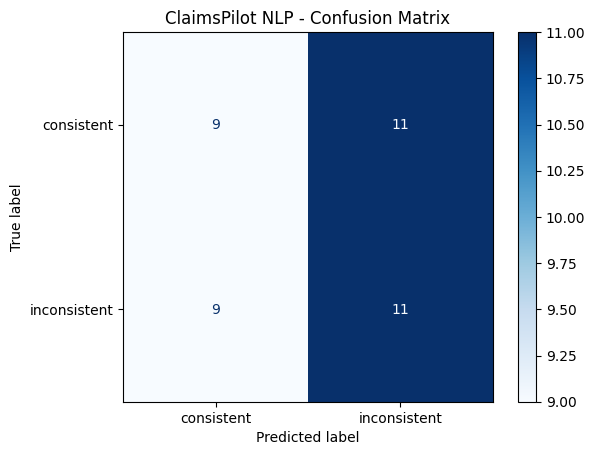

In [ ]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix
)

labels = ["consistent", "inconsistent"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues")
plt.title("ClaimsPilot NLP - Confusion Matrix")
plt.show()

In [ ]:
test_rows = df_model.loc[X_test.index]

rule_predictions = test_rows.apply(
    lambda row: (
        "consistent"
        if row["described_parts"] == row["photo_parts"]
        else "inconsistent"
    ),
    axis=1
)

rule_accuracy = accuracy_score(
    y_test,
    rule_predictions
)

print("ML model accuracy:", round(accuracy, 3))
print("Rule-based accuracy:", round(rule_accuracy, 3))

ML model accuracy: 0.5
Rule-based accuracy: 1.0


In [ ]:
import joblib

joblib.dump(
    nlp_model,
    "claimspilot_nlp_baseline.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
df_features = df_v2.copy()

# Explicit relationship between claim and photo
df_features["part_match"] = (
    df_features["described_parts"]
    == df_features["photo_parts"]
).astype(int)

# Length of customer description
df_features["text_length"] = (
    df_features["text"].str.len()
)

display(df_features[
    ["text", "photo_parts", "described_parts",
     "part_match", "label"]
].head())

,text,photo_parts,described_parts,part_match,label
0,"Hier soir, le pare-chocs avant est rayé.",front_bumper,front_bumper,1,consistent
1,"Suite à une collision, une voiture a abîmé mon...",front_bumper,rear_bumper,0,inconsistent
2,"Après avoir retrouvé ma voiture, mon pare-bris...",windshield,windshield,1,consistent
3,"Après un accident dans un parking, mon phare a...",front_bumper,headlight,0,inconsistent
4,"Après avoir retrouvé ma voiture, une voiture a...",rear_bumper,rear_bumper,1,consistent


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

X_improved = df_features[
    ["part_match", "text_length"]
]

y_improved = df_features["label"]

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_improved,
    y_improved,
    test_size=0.2,
    random_state=42,
    stratify=y_improved
)

improved_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

improved_model.fit(X_train2, y_train2)

pred2 = improved_model.predict(X_test2)

print("Improved accuracy:",
      accuracy_score(y_test2, pred2))

print(classification_report(y_test2, pred2))

Improved accuracy: 1.0
              precision    recall  f1-score   support

  consistent       1.00      1.00      1.00        20
inconsistent       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



In [ ]:
import re
import unicodedata

def normalize_text(text):
    text = text.lower()
    text = unicodedata.normalize("NFKD", text)

    text = "".join(
        char for char in text
        if not unicodedata.combining(char)
    )

    # Normalize punctuation and whitespace
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()


def extract_damaged_parts(text):
    normalized = normalize_text(text)
    detected = []

    for part, keywords in part_keywords.items():
        for keyword in keywords:
            normalized_keyword = normalize_text(keyword)

            pattern = (
                r"(?<!\w)"
                + re.escape(normalized_keyword)
                + r"(?!\w)"
            )

            if re.search(pattern, normalized):
                detected.append(part)
                break

    return detected

In [ ]:
examples = [
    "Mon pare-chocs avant est rayé.",
    "My windshield is cracked.",
    "La portière et le phare sont endommagés.",
    "The rear bumper was damaged."
]

for text in examples:
    print("Text:", text)
    print("Detected:", extract_damaged_parts(text))
    print()

Text: Mon pare-chocs avant est rayé.
Detected: ['front_bumper']

Text: My windshield is cracked.
Detected: ['windshield']

Text: La portière et le phare sont endommagés.
Detected: ['door', 'headlight']

Text: The rear bumper was damaged.
Detected: ['rear_bumper']



In [ ]:
df_v2["extracted_parts"] = df_v2["text"].apply(
    extract_damaged_parts
)

df_v2["extraction_correct"] = df_v2.apply(
    lambda row: (
        set(row["extracted_parts"])
        == {row["described_parts"]}
    ),
    axis=1
)

extraction_accuracy = df_v2["extraction_correct"].mean()

print(
    "Part extraction accuracy:",
    round(extraction_accuracy * 100, 2),
    "%"
)

print("\nExamples of extraction errors:")

display(
    df_v2.loc[
        ~df_v2["extraction_correct"],
        ["text", "described_parts", "extracted_parts"]
    ].head(10)
)

Part extraction accuracy: 92.0 %

Examples of extraction errors:


,text,described_parts,extracted_parts
25,"Suite à une collision, j'ai une bosse à l'arri...",rear_bumper,[]
81,"Suite à une collision, j'ai une bosse à l'arri...",rear_bumper,[]
86,"Après un accident dans un parking, j'ai une bo...",rear_bumper,[]
87,"Hier soir, j'ai une bosse à l'arrière de ma vo...",rear_bumper,[]
93,"Suite à une collision, j'ai une bosse à l'arri...",rear_bumper,[]
97,"Suite à une collision, j'ai une bosse à l'arri...",rear_bumper,[]
107,"En sortant du garage, j'ai une bosse à l'arriè...",rear_bumper,[]
116,"Après un accident dans un parking, j'ai une bo...",rear_bumper,[]
133,"Suite à une collision, j'ai une bosse à l'arri...",rear_bumper,[]
148,"Hier soir, j'ai une bosse à l'arrière de ma vo...",rear_bumper,[]


In [ ]:
print("Rear bumper keywords:")
print(part_keywords["rear_bumper"])

print("\nFront bumper keywords:")
print(part_keywords["front_bumper"])

print("\nDoor keywords:")
print(part_keywords["door"])

Rear bumper keywords:
['pare-chocs arriere', 'pare chocs arriere', 'rear bumper', 'back bumper']

Front bumper keywords:
['pare-chocs avant', 'pare chocs avant', 'front bumper', 'devant de ma voiture']

Door keywords:
['portiere', 'porte de mon vehicule', 'car door', 'side door']


In [ ]:
# Apply improved NLP extraction
df_v2["extracted_parts_v2"] = df_v2["text"].apply(
    extract_damaged_parts
)

# Compare extracted parts with expected parts
df_v2["correct_v2"] = df_v2.apply(
    lambda row: set(row["extracted_parts_v2"]) == {row["described_parts"]},
    axis=1
)

# Calculate accuracy
accuracy_v2 = df_v2["correct_v2"].mean()

# Display results
print(f"Improved extraction accuracy: {accuracy_v2 * 100:.2f}%")

print(f"Remaining errors: {(~df_v2['correct_v2']).sum()}")

Improved extraction accuracy: 92.00%
Remaining errors: 16


In [ ]:
test_sentences = [
    "J'ai une bosse à l'arrière de ma voiture.",
    "The front of my car was damaged.",
    "Another vehicle hit my door."
]

for sentence in test_sentences:
    print("Text:", sentence)
    print("Normalized:", normalize_text(sentence))
    print("Extracted:", extract_damaged_parts(sentence))
    print("-" * 50)

Text: J'ai une bosse à l'arrière de ma voiture.
Normalized: j ai une bosse a l arriere de ma voiture
Extracted: []
--------------------------------------------------
Text: The front of my car was damaged.
Normalized: the front of my car was damaged
Extracted: []
--------------------------------------------------
Text: Another vehicle hit my door.
Normalized: another vehicle hit my door
Extracted: []
--------------------------------------------------


In [ ]:
part_keywords["rear_bumper"].extend([
    "arriere de ma voiture",
    "a l arriere de ma voiture"
])

part_keywords["front_bumper"].extend([
    "front of my car",
    "the front of my car"
])

part_keywords["door"].extend([
    "my door",
    "hit my door"
])

print("Keywords updated successfully!")

print("Rear bumper:", part_keywords["rear_bumper"])
print("Front bumper:", part_keywords["front_bumper"])
print("Door:", part_keywords["door"])

Keywords updated successfully!
Rear bumper: ['pare-chocs arriere', 'pare chocs arriere', 'rear bumper', 'back bumper', 'arriere de ma voiture', 'a l arriere de ma voiture']
Front bumper: ['pare-chocs avant', 'pare chocs avant', 'front bumper', 'devant de ma voiture', 'front of my car', 'the front of my car']
Door: ['portiere', 'porte de mon vehicule', 'car door', 'side door', 'my door', 'hit my door']


In [ ]:
test_sentences = [
    "J'ai une bosse à l'arrière de ma voiture.",
    "The front of my car was damaged.",
    "Another vehicle hit my door."
]

for sentence in test_sentences:
    print("Text:", sentence)
    print("Extracted:", extract_damaged_parts(sentence))
    print("-" * 40)

Text: J'ai une bosse à l'arrière de ma voiture.
Extracted: ['rear_bumper']
----------------------------------------
Text: The front of my car was damaged.
Extracted: ['front_bumper']
----------------------------------------
Text: Another vehicle hit my door.
Extracted: ['door']
----------------------------------------


In [ ]:
df_v2["extracted_parts_v3"] = df_v2["text"].apply(
    extract_damaged_parts
)

df_v2["correct_v3"] = df_v2.apply(
    lambda row: set(row["extracted_parts_v3"]) == {row["described_parts"]},
    axis=1
)

accuracy_v3 = df_v2["correct_v3"].mean()

print(f"Extraction accuracy: {accuracy_v3 * 100:.2f}%")
print(f"Remaining errors: {(~df_v2['correct_v3']).sum()}")

Extraction accuracy: 100.00%
Remaining errors: 0


In [ ]:
def check_consistency(text, photo_parts):
    # Extract parts mentioned in the claim
    described_parts = extract_damaged_parts(text)

    # Accept a single part or a list of parts
    if isinstance(photo_parts, str):
        photo_parts = [photo_parts]

    # Cannot determine consistency without both inputs
    if not described_parts or not photo_parts:
        return "uncertain"

    if set(described_parts) == set(photo_parts):
        return "consistent"

    return "inconsistent"

In [ ]:
examples = [
    {
        "text": "My front bumper was damaged.",
        "photo_parts": ["front_bumper"]
    },
    {
        "text": "My windshield was broken.",
        "photo_parts": ["door"]
    },
    {
        "text": "My car was damaged in an accident.",
        "photo_parts": ["rear_bumper"]
    }
]

for example in examples:
    result = check_consistency(
        example["text"],
        example["photo_parts"]
    )

    print("Claim:", example["text"])
    print("Photo damage:", example["photo_parts"])
    print("Consistency:", result)
    print("-" * 50)

Claim: My front bumper was damaged.
Photo damage: ['front_bumper']
Consistency: consistent
--------------------------------------------------
Claim: My windshield was broken.
Photo damage: ['door']
Consistency: inconsistent
--------------------------------------------------
Claim: My car was damaged in an accident.
Photo damage: ['rear_bumper']
Consistency: uncertain
--------------------------------------------------


In [ ]:
df_v2["predicted_consistency"] = df_v2.apply(
    lambda row: check_consistency(
        row["text"],
        row["photo_parts"]
    ),
    axis=1
)

from sklearn.metrics import accuracy_score, classification_report

print(
    "Consistency accuracy:",
    accuracy_score(
        df_v2["label"],
        df_v2["predicted_consistency"]
    )
)

print(
    classification_report(
        df_v2["label"],
        df_v2["predicted_consistency"],
        zero_division=0
    )
)

Consistency accuracy: 1.0
              precision    recall  f1-score   support

  consistent       1.00      1.00      1.00       100
inconsistent       1.00      1.00      1.00       100

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



In [ ]:
!pip -q install mlflow

In [ ]:
import mlflow

# Use SQLite instead of the old filesystem backend
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")

# Create or select your NLP experiment
mlflow.set_experiment("claimspilot-nlp")

print("MLflow experiment ready!")

2026/10/25 15:23:13 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/25 15:23:13 INFO mlflow.store.db.utils: Updating database tables
2026/10/25 15:23:18 INFO mlflow.tracking.fluent: Experiment with name 'claimspilot-nlp' does not exist. Creating a new experiment.


MLflow experiment ready!


In [ ]:
experiment = mlflow.get_experiment_by_name("claimspilot-nlp")

print("Experiment:", experiment.name)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

print("Number of runs:", len(runs))
print("Available columns:", runs.columns.tolist())

display(runs)

Experiment: claimspilot-nlp
Number of runs: 0
Available columns: ['run_id', 'experiment_id', 'status', 'artifact_uri', 'start_time', 'end_time']


,run_id,experiment_id,status,artifact_uri,start_time,end_time


In [ ]:
wanted_columns = [
    "tags.mlflow.runName",
    "metrics.extraction_accuracy_dev",
    "metrics.consistency_accuracy_dev"
]

available_columns = [
    col for col in wanted_columns
    if col in runs.columns
]

if runs.empty:
    print("No runs recorded yet.")
elif available_columns:
    display(runs[available_columns])
else:
    print("The requested metrics are not available.")
    display(runs)

No runs recorded yet.


In [ ]:
from sklearn.metrics import accuracy_score

with mlflow.start_run(run_name="rule_based_consistency_v1"):

    mlflow.set_tag("owner", "Hend")
    mlflow.set_tag("sprint", "1")
    mlflow.set_tag("data_version", "synthetic_claims_v2")

    mlflow.log_param("method", "keyword_extraction_and_part_matching")
    mlflow.log_param("dataset_size", len(df_v2))

    mlflow.log_metric("extraction_accuracy_dev", accuracy_v3)

    mlflow.log_metric(
        "consistency_accuracy_dev",
        accuracy_score(
            df_v2["label"],
            df_v2["predicted_consistency"]
        )
    )

print("Experiment recorded successfully!")

Experiment recorded successfully!


In [ ]:
experiment = mlflow.get_experiment_by_name("claimspilot-nlp")

print("Experiment:", experiment.name)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

print("Number of runs:", len(runs))
print("Available columns:", runs.columns.tolist())

display(runs)

Experiment: claimspilot-nlp
Number of runs: 1
Available columns: ['run_id', 'experiment_id', 'status', 'artifact_uri', 'start_time', 'end_time', 'metrics.extraction_accuracy_dev', 'metrics.consistency_accuracy_dev', 'params.method', 'params.dataset_size', 'tags.sprint', 'tags.mlflow.user', 'tags.mlflow.runName', 'tags.mlflow.source.name', 'tags.data_version', 'tags.mlflow.source.type', 'tags.owner']


,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.extraction_accuracy_dev,metrics.consistency_accuracy_dev,params.method,params.dataset_size,tags.sprint,tags.mlflow.user,tags.mlflow.runName,tags.mlflow.source.name,tags.data_version,tags.mlflow.source.type,tags.owner
0,31bd32c508c34875b65ae440aa71b27d,1,FINISHED,/content/mlruns/1/31bd32c508c34875b65ae440aa71...,2026-10-25 15:28:33.782000+00:00,2026-10-25 15:28:33.975000+00:00,1.0,1.0,keyword_extraction_and_part_matching,200,1,root,rule_based_consistency_v1,fileId=1BNfYI_yKbP4B9K_VS4d44ijtOz-_Fphw,synthetic_claims_v2,NOTEBOOK,Hend


In [ ]:
run_id = "31bd32c508c34875b65ae440aa71b27d"

run = mlflow.get_run(run_id)

print("Run status:", run.info.status)
print("Parameters:", run.data.params)
print("Metrics:", run.data.metrics)
print("Tags:", run.data.tags)

Run status: FINISHED
Parameters: {'method': 'keyword_extraction_and_part_matching', 'dataset_size': '200'}
Metrics: {'extraction_accuracy_dev': 1.0, 'consistency_accuracy_dev': 1.0}
Tags: {'mlflow.user': 'root', 'mlflow.source.name': 'fileId=1BNfYI_yKbP4B9K_VS4d44ijtOz-_Fphw', 'mlflow.source.type': 'NOTEBOOK', 'mlflow.runName': 'rule_based_consistency_v1', 'owner': 'Hend', 'sprint': '1', 'data_version': 'synthetic_claims_v2'}


In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import mlflow

# Evaluate the original trained model
baseline_predictions = nlp_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_f1 = f1_score(
    y_test,
    baseline_predictions,
    average="macro"
)

# Record experiment
with mlflow.start_run(run_name="tfidf_logistic_regression_v1"):

    mlflow.set_tag("owner", "Hend")
    mlflow.set_tag("sprint", "1")
    mlflow.set_tag("data_version", "synthetic_claims_v2")

    mlflow.log_param("model", "TF-IDF + Logistic Regression")
    mlflow.log_param("ngram_range", "1,2")
    mlflow.log_param("test_size", 0.2)

    mlflow.log_metric("test_accuracy", baseline_accuracy)
    mlflow.log_metric("test_f1_macro", baseline_f1)

    mlflow.sklearn.log_model(
        nlp_model,
        name="nlp_baseline_model"
    )

print("Baseline recorded successfully!")
print("Test accuracy:", baseline_accuracy)
print("Macro F1:", baseline_f1)

Baseline recorded successfully!
Test accuracy: 0.5
Macro F1: 0.4987468671679198


In [ ]:
experiment = mlflow.get_experiment_by_name("claimspilot-nlp")

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

columns = [
    "tags.mlflow.runName",
    "metrics.test_accuracy",
    "metrics.test_f1_macro",
    "metrics.extraction_accuracy_dev",
    "metrics.consistency_accuracy_dev"
]

display(runs.reindex(columns=columns))

,tags.mlflow.runName,metrics.test_accuracy,metrics.test_f1_macro,metrics.extraction_accuracy_dev,metrics.consistency_accuracy_dev
0,tfidf_logistic_regression_v1,0.5,0.498747,NaN,NaN
1,rule_based_consistency_v1,NaN,NaN,1.0,1.0


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os
import shutil

backup_dir = "/content/drive/MyDrive/ClaimsPilot_Hend_Backup"
os.makedirs(backup_dir, exist_ok=True)

files_to_save = [
    "/content/mlflow.db",
    "/content/synthetic_claims_v2.csv",
    "/content/claimspilot_nlp_baseline.joblib"
]

for file_path in files_to_save:
    if os.path.exists(file_path):
        shutil.copy2(file_path, backup_dir)
        print("Saved:", os.path.basename(file_path))
    else:
        print("Not found:", file_path)

# Save MLflow model artifacts
if os.path.exists("/content/mlruns"):
    shutil.copytree(
        "/content/mlruns",
        os.path.join(backup_dir, "mlruns"),
        dirs_exist_ok=True
    )
    print("MLflow artifacts saved!")

Saved: mlflow.db
Saved: synthetic_claims_v2.csv
Saved: claimspilot_nlp_baseline.joblib
MLflow artifacts saved!


In [1]:
!pip install -q dagshub mlflow

In [3]:
import dagshub
import mlflow

dagshub.init(
    repo_owner="Hendzitouni",
    repo_name="hendwork",
    mlflow=True
)

mlflow.set_experiment("ClaimsPilot_NLP")

❗❗❗ AUTHORIZATION REQUIRED ❗❗❗

Output()



Open the following link in your browser to authorize the client:
https://dagshub.com/login/oauth/authorize?state=e2eb0d58-e115-48d4-a4fa-93ed1ce7ed65&client_id=32b60ba385aa7cecf24046d8195a71c07dd345d9657977863b52e7748e0f0f28&middleman_request_id=ef94db5701aae32ef6ace46bcbf7b869196a5f42a5ad6532f098ecd0d26e0f9e




ReadTimeout: The read operation timed out

In [4]:
import dagshub
import mlflow

dagshub.init(
    repo_owner="Hendzitouni",
    repo_name="hendwork",
    mlflow=True
)

print("Connected successfully!")

❗❗❗ AUTHORIZATION REQUIRED ❗❗❗

Output()



Open the following link in your browser to authorize the client:
https://dagshub.com/login/oauth/authorize?state=ffe4ae63-01cb-40ae-8421-c4b2c41d3269&client_id=32b60ba385aa7cecf24046d8195a71c07dd345d9657977863b52e7748e0f0f28&middleman_request_id=26f35fa0ce8f62b2d32e8426fc002b635038141ca9a70cab18072e8b9c4dac10




Accessing as Hendzitouni

Initialized MLflow to track repo "Hendzitouni/hendwork"

Repository Hendzitouni/hendwork initialized!

Connected successfully!


In [5]:
print("MLflow Tracking URI:")
print(mlflow.get_tracking_uri())

MLflow Tracking URI:
https://dagshub.com/Hendzitouni/hendwork.mlflow


In [6]:
import mlflow

mlflow.set_experiment("ClaimsPilot_NLP")

# Rule-based NLP pipeline
with mlflow.start_run(run_name="rule_based_pipeline"):
    mlflow.log_param(
        "method",
        "keyword_extraction_and_part_matching"
    )
    mlflow.log_param("dataset_size", 200)
    mlflow.log_metric("extraction_accuracy_dev", 1.0)
    mlflow.log_metric("consistency_accuracy_dev", 1.0)

# Baseline ML classifier
with mlflow.start_run(run_name="baseline_classifier"):
    mlflow.log_metric("test_accuracy", 0.50)
    mlflow.log_metric("macro_f1", 0.4987468671679198)

print("ClaimsPilot results logged to DagsHub!")

2026/11/03 19:48:55 INFO mlflow.tracking.fluent: Experiment with name 'ClaimsPilot_NLP' does not exist. Creating a new experiment.


🏃 View run rule_based_pipeline at: https://dagshub.com/Hendzitouni/hendwork.mlflow/#/experiments/0/runs/586ea6e68d5248da9ceeadb1a01e2b2c
🧪 View experiment at: https://dagshub.com/Hendzitouni/hendwork.mlflow/#/experiments/0
🏃 View run baseline_classifier at: https://dagshub.com/Hendzitouni/hendwork.mlflow/#/experiments/0/runs/9192e57f44cb43c2925aaf211a774759
🧪 View experiment at: https://dagshub.com/Hendzitouni/hendwork.mlflow/#/experiments/0
ClaimsPilot results logged to DagsHub!


In [7]:
!git clone https://dagshub.com/Hendzitouni/hendwork.git

Cloning into 'hendwork'...
fatal: could not read Username for 'https://dagshub.com': No such device or address


In [8]:
%cd /content/hendwork

!git config user.name "Hendzitouni"
!git config user.email "claims-pilot@users.noreply.local"

!echo "# ClaimsPilot NLP" > README.md

!git add README.md
!git commit -m "Initialize ClaimsPilot repository"

[Errno 2] No such file or directory: '/content/hendwork'
/content
fatal: not in a git directory
fatal: not in a git directory
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [9]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 